<a href="https://colab.research.google.com/github/Areeb575/231A030_NLP-Experiments/blob/main/nlpexp10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from datasets import load_dataset

# Load complete IMDB dataset
dataset = load_dataset("stanfordnlp/imdb")

# Combine train and test
df = pd.concat(
    [dataset["train"].to_pandas(), dataset["test"].to_pandas()],
    ignore_index=True
)

# Rename target column
df = df.rename(columns={"label": "labels"})

print(df.shape)
print(df.columns)
print(df["labels"].value_counts())

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

(50000, 2)
Index(['text', 'labels'], dtype='object')
labels
0    25000
1    25000
Name: count, dtype: int64


In [2]:
#
# 2. CHECK MISSING VALUES AND DUPLICATES
#
print("\nMissing values:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

#
# 3. BASIC TEXT STATISTICS
#
# Using "text" instead of the non-existent "review" column
df["char_count"] = df["text"].astype(str).apply(len)

df["word_count"] = df["text"].astype(str).apply(
    lambda x: len(x.split())
)


Missing values:
text      0
labels    0
dtype: int64

Number of duplicate rows:
418


In [3]:
import re

def clean_text(text):
    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Keep alphabetic characters only
    text = re.sub(r"[^a-z\s]", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Using 'text' instead of the non-existent 'review' column
df["clean_text"] = df["text"].astype(str).apply(clean_text)

print("\nOriginal Review:")
print(df["text"].iloc[0][:500])

print("\nCleaned Review:")
print(df["clean_text"].iloc[0][:500])


Original Review:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent

Cleaned Review:
i rented i am curiousyellow from my video store because of all the controversy that surrounded it when it was first released in i also heard that at first it was seized by us customs if it ever tried to enter this country therefore being a fan of films considered controversial i really had to see this for myself the plot is centered around a young swedish drama student named lena who wants to learn everything she can about life in particular she wants to focus

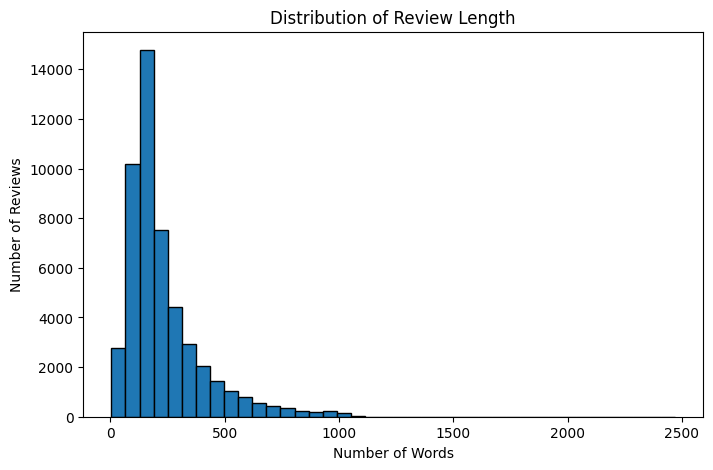

Total number of words: 11342513
Vocabulary size: 162285


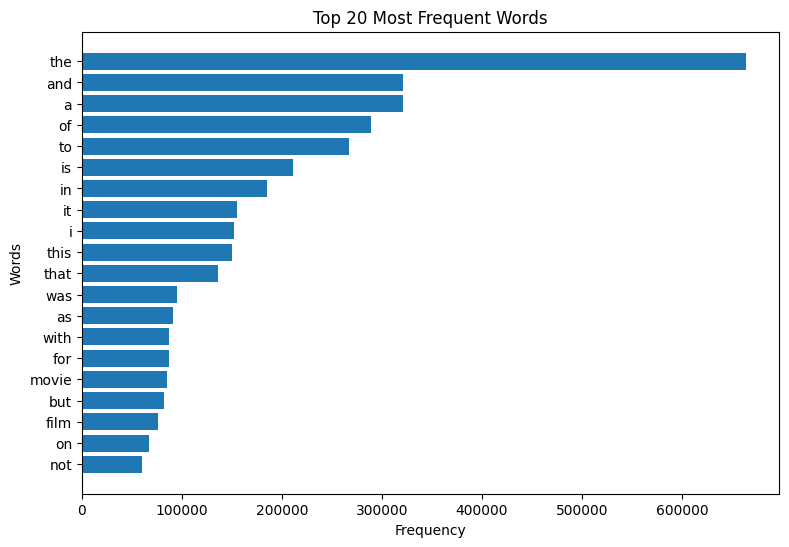

In [4]:
import matplotlib.pyplot as plt
from collections import Counter

#
# 5. DOCUMENT LENGTH DISTRIBUTION
#
plt.figure(figsize=(8, 5))
plt.hist(df["word_count"], bins=40, edgecolor="black")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.title("Distribution of Review Length")
plt.show()

#
# 6. CREATE WORD LIST
#
all_words = " ".join(df["clean_text"]).split()

print("Total number of words:", len(all_words))
print("Vocabulary size:", len(set(all_words)))

#
# 7. MOST FREQUENT WORDS
#
word_freq = Counter(all_words)
top_words = word_freq.most_common(20)
words = [word for word, count in top_words]
counts = [count for word, count in top_words]

plt.figure(figsize=(9, 6))
plt.barh(words[::-1], counts[::-1])
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.title("Top 20 Most Frequent Words")
plt.show()

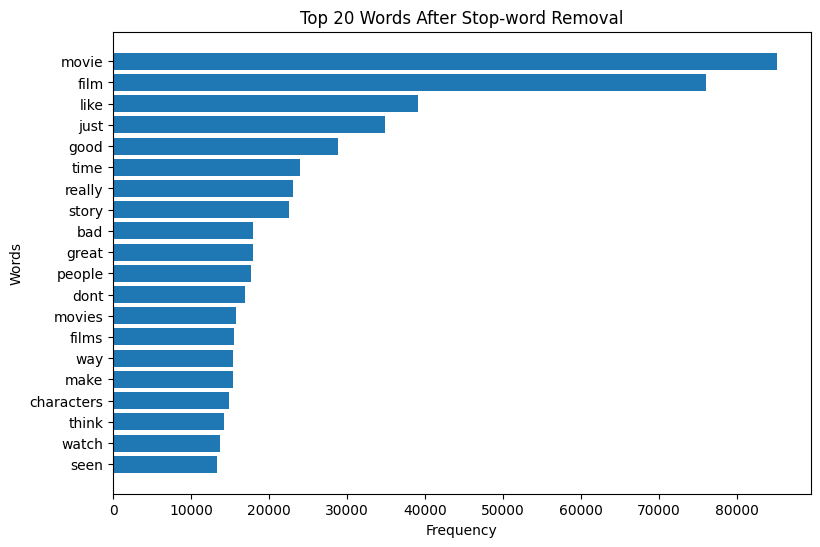

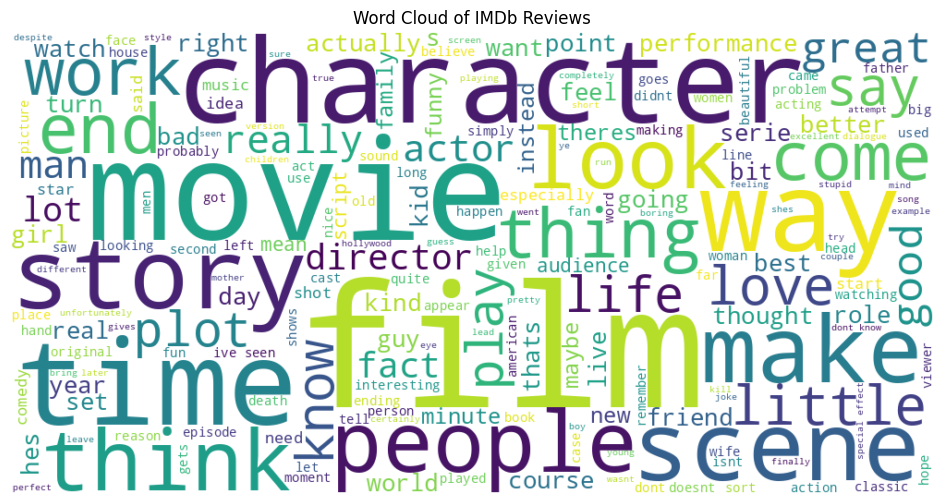

In [5]:
from sklearn.feature_extraction.text import CountVectorizer
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from collections import Counter

#
# 8. REMOVE STOP WORDS
#
vectorizer = CountVectorizer(stop_words="english")
vectorizer.fit(df["clean_text"])
stop_words = vectorizer.get_stop_words()

filtered_words = [word for word in all_words if word not in stop_words]
filtered_freq = Counter(filtered_words)

top_filtered = filtered_freq.most_common(20)
words = [word for word, count in top_filtered]
counts = [count for word, count in top_filtered]

plt.figure(figsize=(9, 6))
plt.barh(words[::-1], counts[::-1])
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.title("Top 20 Words After Stop-word Removal")
plt.show()

#
# 9. WORD CLOUD
#
clean_text_combined = " ".join(filtered_words)

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(clean_text_combined)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of IMDb Reviews")
plt.show()